# EDA – CommonLit Readability

Перед запуском: из корня репо выполнить `python -m src.data`, чтобы создать `data/folds.csv`.

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from src.utils import load_config, resolve
from src.data import load_train, load_test, load_folds
from src.features import build_features

cfg = load_config()
FIG = resolve(cfg["paths"]["figures"])
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=120)
    plt.show()


train = load_train(cfg)
test = load_test(cfg)

## 1. Обзор и пропуски

In [3]:
print(train.shape, test.shape)
display(train.head())
display(pd.concat([train.isna().mean().rename("train"), test.isna().mean().rename("test")], axis=1))

(2834, 6) (7, 4)


,id,url_legal,license,excerpt,target,standard_error
0,c12129c31,NaN,NaN,"When the young people returned to the ballroom, it presented a decidedly changed appearance. Instead of an interior scene, it was a winter landscape.\nThe floor was covered with snow-white canvas,...",-0.340259,0.464009
1,85aa80a4c,NaN,NaN,"All through dinner time, Mrs. Fayre was somewhat silent, her eyes resting on Dolly with a wistful, uncertain expression. She wanted to give the child the pleasure she craved, but she had hard work...",-0.315372,0.480805
2,b69ac6792,NaN,NaN,"As Roger had predicted, the snow departed as quickly as it came, and two days after their sleigh ride there was scarcely a vestige of white on the ground. Tennis was again possible and a great gam...",-0.580118,0.476676
3,dd1000b26,NaN,NaN,"And outside before the palace a great garden was walled round, filled full of stately fruit-trees, gray olives and sweet figs, and pomegranates, pears, and apples, which bore the whole year round....",-1.054013,0.450007
4,37c1b32fb,NaN,NaN,"Once upon a time there were Three Bears who lived together in a house of their own in a wood. One of them was a Little, Small, Wee Bear; and one was a Middle-sized Bear, and the other was a Great,...",0.247197,0.510845


,train,test
id,0.000000,0.000000
url_legal,0.707128,0.571429
license,0.707128,0.571429
excerpt,0.000000,0.000000
target,0.000000,NaN
standard_error,0.000000,NaN


**Выводы:**

Так как данные с каггла, тест не размечен, работать будем с трейном, url_legal и license много где отсутствуют, как данные испольтзованы не будут (дополнительно сквозь их наличие может проходить лик того, каким именно является текст). В остальном в трейне пропусков нет.

## 2. Таргет и standard_error

,target,standard_error
count,2834.000000,2834.000000
mean,-0.959319,0.491435
std,1.033579,0.034818
min,-3.676268,0.000000
25%,-1.690320,0.468543
50%,-0.912190,0.484721
75%,-0.202540,0.506268
max,1.711390,0.649671


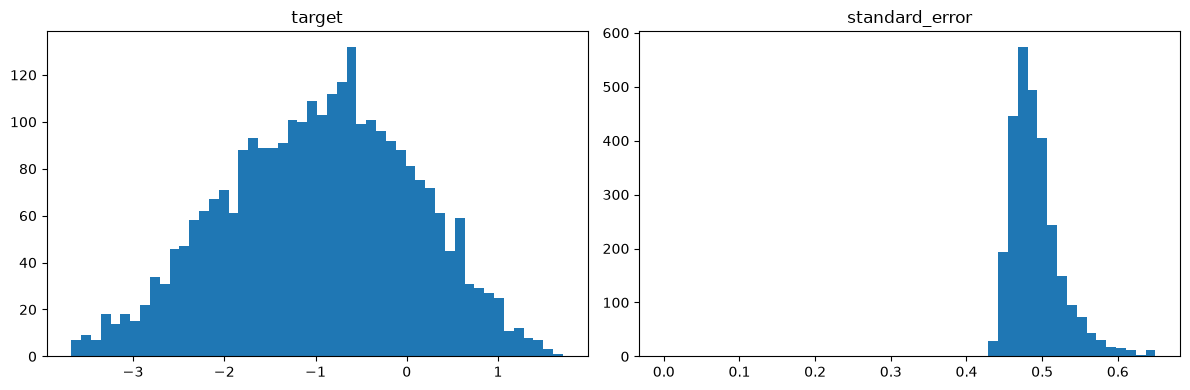

In [4]:
display(train[["target", "standard_error"]].describe())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train["target"], bins=50)
ax[0].set_title("target")
ax[1].hist(train["standard_error"], bins=50)
ax[1].set_title("standard_error")
save("target_se_hist")

**Выводы:** 

Распределение target: среднее -0.96, std 1.03, диапазон от -3.68 до 1.71. Оно унимодальное, близко к нормальному, с небольшим хвостом в сторону сложных текстов.

Константа среднего даст RMSE около 1.03.

standard_error сосредоточен в диапазоне 0.43–0.65, медиана 0.48. Есть одна аномалия с SE = 0 (референтный текст, относительно которого строилась шкала Bradley–Terry)

## 3. Шум разметки, опорный текст, крайние примеры

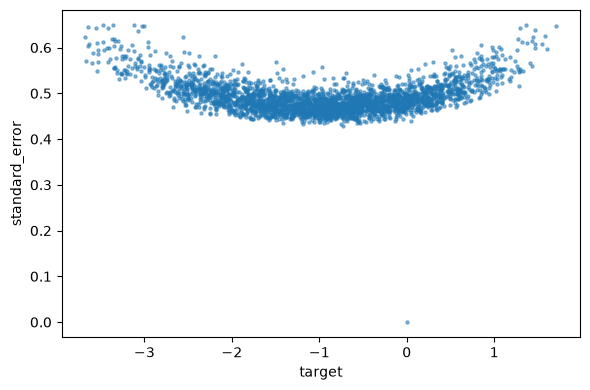

,id,target,standard_error,excerpt
106,436ce79fe,0.000000,0.000000,"The sun was shining in a cloudless sky, and no shadows lay on the mountain, and all day long they watched and waited, and at last, when the birds were singing their farewell song to the evening st..."
2483,d7ea6fa85,-0.725055,0.428233,"It was characteristic of Tom Slade that he liked to go off alone occasionally for a ramble in the woods. It was not that he liked the scouts less, but rather that he liked the woods more. It was h..."
196,b9cca6661,-0.748452,0.433000,"The principal business of the people of this country was the raising of sweet marjoram. The soil and climate were admirably adapted to the culture of the herb, and fields and fields of it were to ..."


,target,excerpt
2829,1.71139,"When you think of dinosaurs and where they lived, what do you picture? Do you see hot, steamy swamps, thick jungles, or sunny plains? Dinosaurs lived in those places, yes. But did you know that so..."
981,1.59787,"For her last birthday, Sisanda had a special treat – her parents got permission for her to have a party at the game reserve. The giraffes at the reserve were curious about this group of people. Th..."


,target,excerpt
1705,-3.676268,"The commutator is peculiar, consisting of only three segments of a copper ring, while in the simplest of other continuous current generators several times that number exist, and frequently 120! se..."
1128,-3.668360,"The Dunwich horror itself came between Lammas and the equinox in 1928, and Dr. Armitage was among those who witnessed its monstrous prologue. He had heard, meanwhile, of Whateley's grotesque trip ..."


In [5]:
plt.figure(figsize=(6, 4))
plt.scatter(train["target"], train["standard_error"], s=5, alpha=0.5)
plt.xlabel("target")
plt.ylabel("standard_error")
save("target_vs_se")
display(train.nsmallest(3, "standard_error")[["id", "target", "standard_error", "excerpt"]])
display(train.nlargest(2, "target")[["target", "excerpt"]])
display(train.nsmallest(2, "target")[["target", "excerpt"]])

**Выводы:** 

U-образная зависимость: SE растет к краям шкалы. Оценки самых легких и самых сложных текстов наименее надежны, и модель на краях будет ошибаться сильнее.

Крайние примеры осмысленны. Самые легкие – детские тексты. Самые сложные – текст XIX века и Лавкрафт.

## 4. Readability-признаки и корреляции с таргетом

In [6]:
feats = build_features(train["excerpt"])
corr = pd.DataFrame({
    "pearson": feats.apply(lambda c: pearsonr(c, train["target"])[0]),
    "spearman": feats.apply(lambda c: spearmanr(c, train["target"])[0]),
}).sort_values("spearman")
display(feats.describe().T)
display(corr)

,count,mean,std,min,25%,50%,75%,max
n_chars,2834.0,971.732886,117.257578,669.000000,885.000000,971.000000,1058.000000,1341.000000
n_words,2834.0,173.808751,17.182194,113.000000,160.000000,175.000000,189.000000,216.000000
n_sentences,2834.0,9.444601,4.223035,2.000000,7.000000,8.000000,11.000000,39.000000
words_per_sentence,2834.0,21.590320,9.180936,4.743590,15.818182,20.375000,25.625000,102.000000
chars_per_word,2834.0,4.432478,0.434894,3.142105,4.126984,4.385047,4.698112,6.883871
syllables_per_word,2834.0,1.428997,0.179938,1.006897,1.295366,1.396689,1.540116,2.509677
long_word_share,2834.0,0.182173,0.076230,0.000000,0.127578,0.175071,0.228494,0.561290
polysyllable_share,2834.0,0.096652,0.065975,0.000000,0.045049,0.084984,0.135101,0.445161
type_token_ratio,2834.0,0.606204,0.060223,0.204545,0.572139,0.611765,0.648276,0.767742
flesch_reading_ease,2834.0,63.608942,18.492921,-31.743871,52.076230,64.803282,77.182413,109.596765


,pearson,spearman
dale_chall,-0.531742,-0.548805
flesch_kincaid_grade,-0.500184,-0.540354
long_word_share,-0.473538,-0.489674
syllables_per_word,-0.443146,-0.468915
polysyllable_share,-0.438472,-0.467501
chars_per_word,-0.421182,-0.437637
words_per_sentence,-0.336106,-0.389200
n_chars,-0.362782,-0.355838
type_token_ratio,-0.184029,-0.189939
n_words,-0.120434,-0.115429


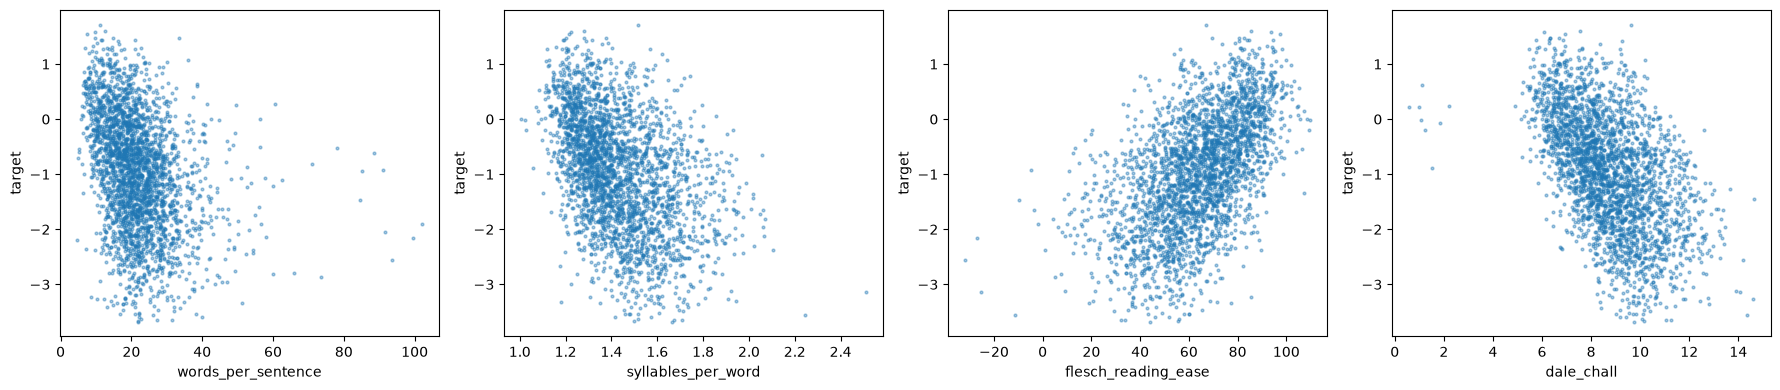

In [7]:
cols = ["words_per_sentence", "syllables_per_word", "flesch_reading_ease", "dale_chall"]
fig, ax = plt.subplots(1, len(cols), figsize=(18, 4))
for a, c in zip(ax, cols):
    a.scatter(feats[c], train["target"], s=4, alpha=0.4)
    a.set_xlabel(c)
    a.set_ylabel("target")
save("readability_vs_target")

**Выводы:** 

Все признаки длины и сложности слов связаны с target умеренно, Spearman от 0.44 до 0.56.
Лучшие одиночные признаки:
Flesch Reading Ease: Spearman 0.56;
Dale–Chall: -0.55;
Flesch–Kincaid: -0.54.
Объясненная дисперсия: один признак объясняет около 30% дисперсии. 
Количество предложений коррелирует положительно, потому что длина отрывков почти фиксирована: больше предложений означает короче предложения и легче текст.

## 5. url_legal / license

Недоступны на inference (пустые в тесте) – как признаки не используются. Наличие url – прокси для современных текстов.

has_url
False    0.707128
True     0.292872
Name: proportion, dtype: float64

,count,mean,std,min,25%,50%,75%,max
has_url,,,,,,,,
False,2004.0,-1.082035,1.024972,-3.676268,-1.800242,-1.052550,-0.340102,1.465592
True,830.0,-0.663027,0.994025,-3.549190,-1.369915,-0.620196,0.067141,1.711390


license
CC BY 4.0                391
CC BY-SA 3.0 and GFDL    196
CC BY-SA 3.0             192
CC BY-NC-SA 2.0           26
CC BY 3.0                  7
CC BY-NC-SA 4.0            4
CC BY-NC-ND 4.0            3
CC BY-NC                   2
CC BY NC-SA 2.0            2
CC BY-NC-SA 3.0            2
Name: count, dtype: int64

0
simple.wikipedia.org        196
kids.frontiersin.org        191
en.wikipedia.org            176
www.africanstorybook.org    164
www.commonlit.org            41
freekidsbooks.org            19
www.digitallibrary.io        19
en.wikibooks.org              8
static.ehe.osu.edu            6
drive.google.com              3
Name: count, dtype: int64

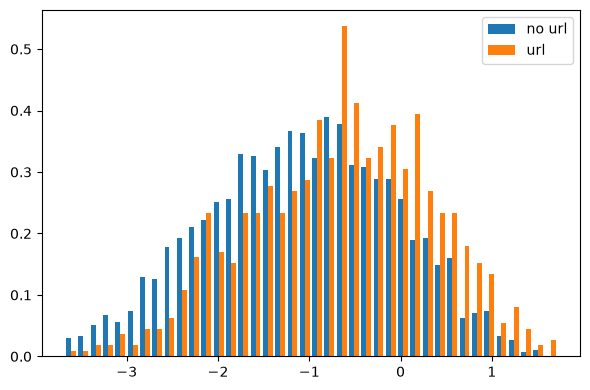

In [8]:
train["has_url"] = train["url_legal"].notna()
display(train["has_url"].value_counts(normalize=True))
display(train.groupby("has_url")["target"].describe())
display(train["license"].value_counts().head(10))
display(train["url_legal"].dropna().str.extract(r"https?://([^/]+)")[0].value_counts().head(10))
plt.figure(figsize=(6, 4))
plt.hist([train.loc[~train.has_url, "target"], train.loc[train.has_url, "target"]],
         bins=40, density=True, label=["no url", "url"])
plt.legend()
save("target_by_url")

**Выводы:** 

URL есть у 29.3% текстов. Тексты с URL заметно легче: среднее -0.66 против -1.08, разница около 0.4 std.

Признак коррелирует с таргетом, но на inference недоступен. Его использование завысило бы метрики и не перенеслось бы на тест.

Авторы пишут, что в тесте доля современных текстов выше, поэтому качество на срезе has_url = True – возможно важная метрика.

## 6. Дубликаты и почти-дубликаты (риск лика между фолдами)

In [9]:
print("exact duplicates:", train["excerpt"].duplicated().sum())
X = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(train["excerpt"])
sim = cosine_similarity(X)
np.fill_diagonal(sim, 0)
i, j = np.where(np.triu(sim) > 0.5)
pairs = pd.DataFrame({"i": i, "j": j, "sim": sim[i, j]}).sort_values("sim", ascending=False)
print("pairs with sim > 0.5:", len(pairs))
for _, r in pairs.head(5).iterrows():
    a, b = train.iloc[int(r.i)], train.iloc[int(r.j)]
    print(f"{r.sim:.3f} | target {a.target:.2f} vs {b.target:.2f}")
    print(a.excerpt[:150])
    print(b.excerpt[:150])
    print()

exact duplicates: 0
pairs with sim > 0.5: 3
1.000 | target 0.81 vs 0.10
Goat, Dog and Cow were great friends. One day they went on a journey in a taxi. They reached the end of their journey. The driver asked them to pay th
Goat, Dog and Cow were great friends. One day they went on a journey in a taxi. They reached the end of their journey. The driver asked them to pay th

0.936 | target -0.81 vs -0.86
When the two friends had thus become reconciled, they examined the cub, and saw that it had a slight wound in its foot, and could not walk; and while 
When the two friends had thus become reconciled, they examined the cub, and saw that it had a slight wound in its foot, and could not walk; and while 

0.693 | target 0.28 vs -0.27
Either the well was very deep, or she fell very slowly, for she had plenty of time as she went down to look about her, and to wonder what was going to
In another moment down went Alice after it, never once considering how in the world she was to get out again.
Th

**Выводы:** 

Точных дубликатов нет. Похожих пар (cosine > 0.5) всего 3.
Пара с похожестью 1.0: почти идентичный текст получил target 0.81 и 0.10. Видимо шум разметки порядка 0.7.

Пара 0.94: близкие target, -0.81 и -0.86.

Пара 0.69: соседние отрывки "Алисы в стране чудес" – не дубликат.

3 пары из 2834 на оценку практически не влияют, GroupKFold не нужен. 

При этом есть лик другого рода: разные отрывки одной книги могут попасть в разные фолды, и модель частично выучит стиль автора. Для 70% текстов источник неизвестен, поэтому сгруппировать их нельзя –  ограничение pflfxb.

## 7. Проверка фолдов

In [11]:
folds = load_folds(cfg)
assert (folds["id"] == train["id"]).all()
for seed in cfg["cv"]["seeds"]:
    display(train.assign(fold=folds[f"fold_{seed}"]).groupby("fold")["target"].agg(["count", "mean", "std"]).round(3))

,count,mean,std
fold,,,
0,567,-0.956,1.021
1,567,-0.951,1.044
2,567,-0.957,1.041
3,567,-0.958,1.015
4,566,-0.974,1.049


,count,mean,std
fold,,,
0,567,-0.953,1.013
1,567,-0.959,1.064
2,567,-0.962,1.036
3,567,-0.970,1.035
4,566,-0.953,1.022


,count,mean,std
fold,,,
0,567,-0.960,1.053
1,567,-0.953,1.023
2,567,-0.967,1.035
3,567,-0.962,1.027
4,566,-0.955,1.033


**Выводы:** 

Стратификация по 10 квантилям таргета работает.

По всем 3 сидам фолды по 566–567 объектов, средние таргета от -0.95 до -0.97, std от 1.01 до 1.06

## Выводы EDA

Регрессия по одному тексту. Единственный вход – excerpt, метаданные недоступны на inference.

Основная метрика – RMSE. Ориентир dummy около 1.03.

Шум разметки значителен.

Классические readability-формулы объясняют около 30% дисперсии (TF-IDF должен быть заметно лучше, иначе гипотеза о ценности лексики не подтвердится).

Главный риск лика – url_legal и license. Используем их только для анализа срезов.

Дубликаты пренебрежимы, стратифицированный 5-fold x 3 сида корректен. Ограничение – возможная близость отрывков одного источника.

Сдвиг на тесте: в тесте больше современных текстов, поэтому качество на срезе с URL отслеживаем отдельно.